In [1]:

# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/johnarevalo/mmimdb/metadata.npy
/kaggle/input/datasets/johnarevalo/mmimdb/multimodal_imdb.hdf5


## 1. Load data

In [2]:
import h5py, numpy as np
path = '/kaggle/input/datasets/johnarevalo/mmimdb/'
f = h5py.File(path + 'multimodal_imdb.hdf5', 'r')
for k in f.keys():
    print(k, f[k].shape, f[k].dtype)
print(dict(f.attrs))
meta = np.load(path + 'metadata.npy', allow_pickle=True)
print(type(meta), getattr(meta, 'shape', None))

features (25959, 300) float32
genres (25959, 23) int32
images (25959, 3, 256, 160) int32
imdb_ids (25959,) |S7
sequences (25959,) object
three_grams (25959, 9946) float32
vgg_features (25959, 4096) float32
word_grams (25959, 13253) float32
{'split': array([(b'train', b'features',     0, 15552, <HDF5 object reference (null)>,  True, b'.'),
       (b'train', b'genres',     0, 15552, <HDF5 object reference (null)>,  True, b'.'),
       (b'train', b'images',     0, 15552, <HDF5 object reference (null)>,  True, b'.'),
       (b'train', b'imdb_ids',     0, 15552, <HDF5 object reference (null)>,  True, b'.'),
       (b'train', b'sequences',     0, 15552, <HDF5 object reference (null)>,  True, b'.'),
       (b'train', b'three_grams',     0, 15552, <HDF5 object reference (null)>,  True, b'.'),
       (b'train', b'vgg_features',     0, 15552, <HDF5 object reference (null)>,  True, b'.'),
       (b'train', b'word_grams',     0, 15552, <HDF5 object reference (null)>,  True, b'.'),
       (b'dev', 

In [3]:
X_img = f['vgg_features'][:]   # poster features
X_txt = f['features'][:]       # plot features
Y = f['genres'][:]             # labels
tr, dv, te = slice(0,15552), slice(15552,18160), slice(18160,25959)
print(X_img.shape, X_txt.shape, Y.shape)
print('Avg genres per movie:', Y.sum(1).mean())
m = meta.item() if meta.shape == () else meta
print(m.keys() if isinstance(m, dict) else m[:5])

(25959, 4096) (25959, 300) (25959, 23)
Avg genres per movie: 2.484648869370931
dict_keys(['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word'])


## 2. Exploratory data analysis

Drama         13967 (53.8%)
Comedy         8592 (33.1%)
Romance        5364 (20.7%)
Thriller       5192 (20.0%)
Crime          3838 (14.8%)
Action         3550 (13.7%)
Adventure      2710 (10.4%)
Horror         2703 (10.4%)
Documentary    2082 (8.0%)
Mystery        2057 (7.9%)
Sci-Fi         1991 (7.7%)
Fantasy        1933 (7.4%)
Family         1668 (6.4%)
Biography      1343 (5.2%)
War            1335 (5.1%)
History        1143 (4.4%)
Music          1045 (4.0%)
Animation       997 (3.8%)
Musical         841 (3.2%)
Western         705 (2.7%)
Sport           634 (2.4%)
Short           471 (1.8%)
Film-Noir       338 (1.3%)


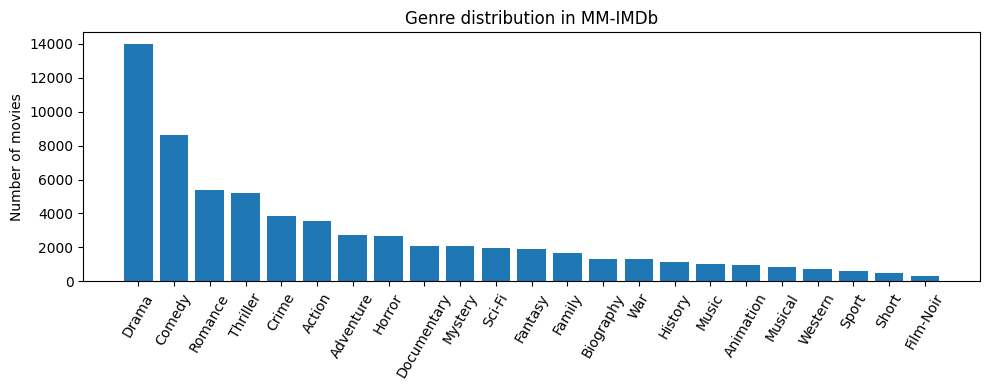

In [4]:
import matplotlib.pyplot as plt
genres = ['Drama','Comedy','Romance','Thriller','Crime','Action','Adventure','Horror',
          'Documentary','Mystery','Sci-Fi','Fantasy','Family','Biography','War','History',
          'Music','Animation','Musical','Western','Sport','Short','Film-Noir']
counts = Y.sum(0)
for g, c in zip(genres, counts): print(f'{g:12s} {c:6d} ({100*c/len(Y):.1f}%)')
plt.figure(figsize=(10,4)); plt.bar(genres, counts); plt.xticks(rotation=60)
plt.ylabel('Number of movies'); plt.title('Genre distribution in MM-IMDb')
plt.tight_layout(); plt.savefig('genre_distribution.png', dpi=150); plt.show()

Drama         13967 (53.8%)
Comedy         8592 (33.1%)
Romance        5364 (20.7%)
Thriller       5192 (20.0%)
Crime          3838 (14.8%)
Action         3550 (13.7%)
Adventure      2710 (10.4%)
Horror         2703 (10.4%)
Documentary    2082 (8.0%)
Mystery        2057 (7.9%)
Sci-Fi         1991 (7.7%)
Fantasy        1933 (7.4%)
Family         1668 (6.4%)
Biography      1343 (5.2%)
War            1335 (5.1%)
History        1143 (4.4%)
Music          1045 (4.0%)
Animation       997 (3.8%)
Musical         841 (3.2%)
Western         705 (2.7%)
Sport           634 (2.4%)
Short           471 (1.8%)
Film-Noir       338 (1.3%)


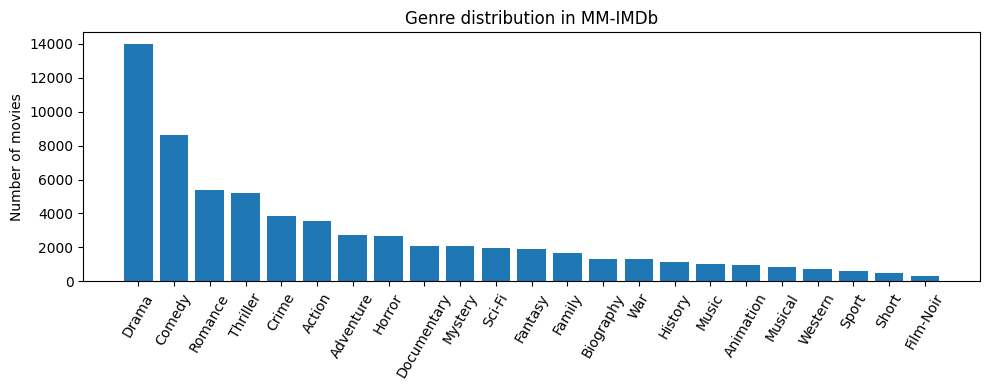

In [5]:
import matplotlib.pyplot as plt
genres = ['Drama','Comedy','Romance','Thriller','Crime','Action','Adventure','Horror',
          'Documentary','Mystery','Sci-Fi','Fantasy','Family','Biography','War','History',
          'Music','Animation','Musical','Western','Sport','Short','Film-Noir']
counts = Y.sum(0)
for g, c in zip(genres, counts): print(f'{g:12s} {c:6d} ({100*c/len(Y):.1f}%)')
plt.figure(figsize=(10,4)); plt.bar(genres, counts); plt.xticks(rotation=60)
plt.ylabel('Number of movies'); plt.title('Genre distribution in MM-IMDb')
plt.tight_layout(); plt.savefig('genre_distribution.png', dpi=150); plt.show()

## 3. Data quality and preprocessing

NaNs (img, txt): 0 0
All-zero plot vectors: 0
Movies with 0 genres: 0


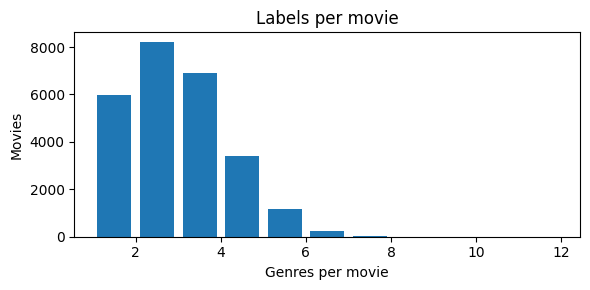

Train/Dev/Test: 15552 2608 7799


In [6]:
from sklearn.preprocessing import StandardScaler
print('NaNs (img, txt):', np.isnan(X_img).sum(), np.isnan(X_txt).sum())
print('All-zero plot vectors:', (np.abs(X_txt).sum(1)==0).sum())
print('Movies with 0 genres:', (Y.sum(1)==0).sum())
plt.figure(figsize=(6,3)); plt.hist(Y.sum(1), bins=range(1,13), rwidth=0.8)
plt.xlabel('Genres per movie'); plt.ylabel('Movies'); plt.title('Labels per movie')
plt.tight_layout(); plt.savefig('labels_per_movie.png', dpi=150); plt.show()
sc_i = StandardScaler().fit(X_img[tr]); sc_t = StandardScaler().fit(X_txt[tr])
Xi = sc_i.transform(X_img).astype('float32'); Xt = sc_t.transform(X_txt).astype('float32')
print('Train/Dev/Test:', Y[tr].shape[0], Y[dv].shape[0], Y[te].shape[0])

## 4. Model and evaluation functions

In [7]:
import torch, torch.nn as nn
from sklearn.metrics import f1_score, average_precision_score
dev_ = 'cuda' if torch.cuda.is_available() else 'cpu'
Yf = Y.astype('float32')
pw = torch.tensor((Yf[tr]==0).sum(0) / Yf[tr].sum(0)).float().clamp(max=10).to(dev_)

def mlp(d_in, h=512, p=0.5):
    return nn.Sequential(nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, 23))

def train(X, seed=0, epochs=40, lr=1e-3, wd=1e-4):
    torch.manual_seed(seed); np.random.seed(seed)
    m = mlp(X.shape[1]).to(dev_)
    opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pw)
    Xtr, Ytr = torch.tensor(X[tr]).to(dev_), torch.tensor(Yf[tr]).to(dev_)
    Xdv, Ydv = torch.tensor(X[dv]).to(dev_), torch.tensor(Yf[dv]).to(dev_)
    hist, best, best_state = {'train': [], 'dev': []}, 1e9, None
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 256):
            idx = perm[i:i+256]; opt.zero_grad()
            loss = lossf(m(Xtr[idx]), Ytr[idx]); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad():
            hist['train'].append(lossf(m(Xtr), Ytr).item())
            hist['dev'].append(lossf(m(Xdv), Ydv).item())
        if hist['dev'][-1] < best:
            best = hist['dev'][-1]; best_state = {k: v.clone() for k, v in m.state_dict().items()}
    m.load_state_dict(best_state)
    return m, hist

def predict(m, X):
    m.eval()
    with torch.no_grad():
        return torch.sigmoid(m(torch.tensor(X).to(dev_))).cpu().numpy()

def tune_thresholds(P, Yt):
    ts = np.arange(0.05, 0.95, 0.05)
    return np.array([ts[np.argmax([f1_score(Yt[:, j], P[:, j] >= t, zero_division=0) for t in ts])] for j in range(23)])

def evaluate(P, Yt, th):
    Yp = (P >= th).astype(int)
    return {'micro_F1':   round(f1_score(Yt, Yp, average='micro',   zero_division=0), 4),
            'macro_F1':   round(f1_score(Yt, Yp, average='macro',   zero_division=0), 4),
            'samples_F1': round(f1_score(Yt, Yp, average='samples', zero_division=0), 4),
            'mAP':        round(average_precision_score(Yt, P, average='macro'), 4)}
print('Ready, using', dev_)

Ready, using cuda


Poster-only: {'micro_F1': 0.4525, 'macro_F1': 0.3338, 'samples_F1': 0.4462, 'mAP': np.float64(0.2967)}


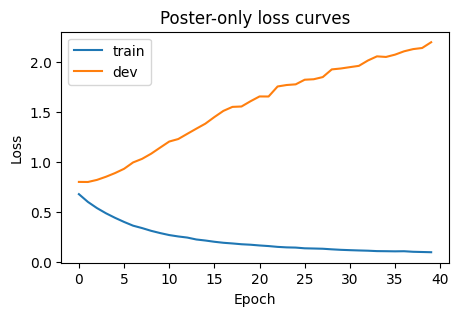

In [8]:
m_img, h_img = train(Xi)
th_img = tune_thresholds(predict(m_img, Xi[dv]), Y[dv])
P_img_te = predict(m_img, Xi[te])
res_img = evaluate(P_img_te, Y[te], th_img); print('Poster-only:', res_img)
plt.figure(figsize=(5,3)); plt.plot(h_img['train'], label='train'); plt.plot(h_img['dev'], label='dev')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Poster-only loss curves'); plt.legend(); plt.show()

## 5. Unimodal baselines

Poster {'micro_F1': 0.4581, 'macro_F1': 0.3433, 'samples_F1': 0.4543, 'mAP': np.float64(0.3075)}


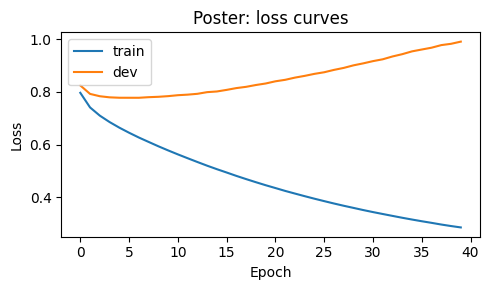

Plot {'micro_F1': 0.6085, 'macro_F1': 0.5275, 'samples_F1': 0.6009, 'mAP': np.float64(0.5231)}


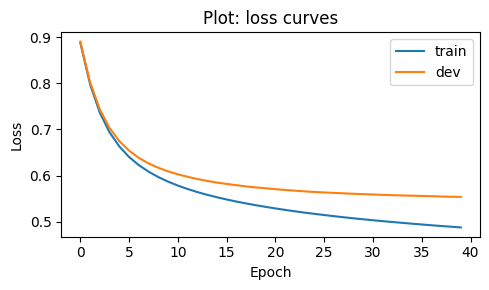

In [9]:
results = {}
def run(X, name, **kw):
    m, h = train(X, **kw)
    P_dv, P_te = predict(m, X[dv]), predict(m, X[te])
    th = tune_thresholds(P_dv, Y[dv]); results[name] = evaluate(P_te, Y[te], th)
    print(name, results[name])
    plt.figure(figsize=(5,3)); plt.plot(h['train'], label='train'); plt.plot(h['dev'], label='dev')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title(f'{name}: loss curves'); plt.legend()
    plt.tight_layout(); plt.savefig(f'loss_{name}.png', dpi=150); plt.show()
    return m, P_dv, P_te

m_img, Pdv_img, Pte_img = run(Xi, 'Poster', lr=1e-4, wd=1e-3)
m_txt, Pdv_txt, Pte_txt = run(Xt, 'Plot',   lr=1e-4, wd=1e-3)

## 6. Early and late fusion

Early_fusion {'micro_F1': 0.6039, 'macro_F1': 0.5221, 'samples_F1': 0.5935, 'mAP': np.float64(0.5191)}


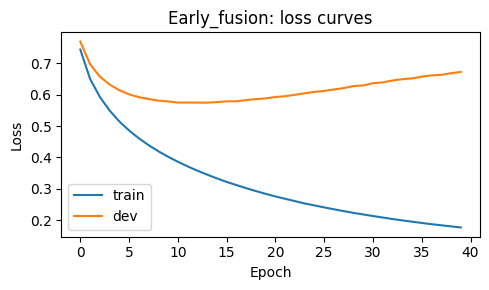

Best poster weight (alpha): 0.4


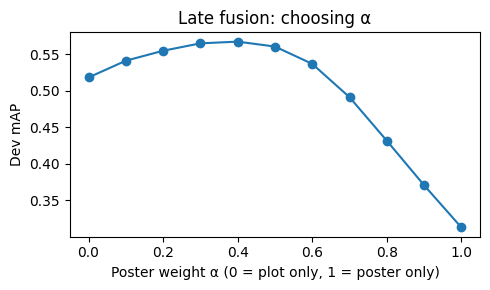

Late_fusion {'micro_F1': 0.6249, 'macro_F1': 0.5563, 'samples_F1': 0.6145, 'mAP': np.float64(0.5621)}
              micro_F1  macro_F1  samples_F1     mAP
Poster          0.4581    0.3433      0.4543  0.3075
Plot            0.6085    0.5275      0.6009  0.5231
Early_fusion    0.6039    0.5221      0.5935  0.5191
Late_fusion     0.6249    0.5563      0.6145  0.5621


In [10]:
# ---- Early fusion: join both feature vectors, train one model ----
Xe = np.concatenate([Xi, Xt], axis=1)
m_early, Pdv_early, Pte_early = run(Xe, 'Early_fusion', lr=1e-4, wd=1e-3)

# ---- Late fusion: weighted average of the two models' probabilities ----
alphas = np.arange(0, 1.01, 0.1)
dev_map = [average_precision_score(Y[dv], a*Pdv_img + (1-a)*Pdv_txt, average='macro') for a in alphas]
a = alphas[np.argmax(dev_map)]; print('Best poster weight (alpha):', round(a, 1))
plt.figure(figsize=(5,3)); plt.plot(alphas, dev_map, marker='o')
plt.xlabel('Poster weight α (0 = plot only, 1 = poster only)'); plt.ylabel('Dev mAP')
plt.title('Late fusion: choosing α'); plt.tight_layout(); plt.savefig('late_fusion_alpha.png', dpi=150); plt.show()
Pdv_late, Pte_late = a*Pdv_img + (1-a)*Pdv_txt, a*Pte_img + (1-a)*Pte_txt
results['Late_fusion'] = evaluate(Pte_late, Y[te], tune_thresholds(Pdv_late, Y[dv]))
print('Late_fusion', results['Late_fusion'])

import pandas as pd
print(pd.DataFrame(results).T)

## 7. Early fusion with PCA (balancing modalities

Poster variance kept by PCA-300: 0.663
Early_fusion_PCA {'micro_F1': 0.6299, 'macro_F1': 0.561, 'samples_F1': 0.6213, 'mAP': np.float64(0.5658)}


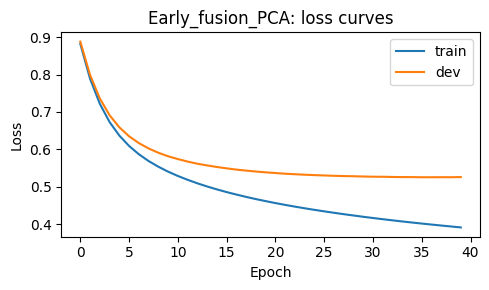

                  micro_F1  macro_F1  samples_F1     mAP
Poster              0.4581    0.3433      0.4543  0.3075
Plot                0.6085    0.5275      0.6009  0.5231
Early_fusion        0.6039    0.5221      0.5935  0.5191
Late_fusion         0.6249    0.5563      0.6145  0.5621
Early_fusion_PCA    0.6299    0.5610      0.6213  0.5658


In [11]:
from sklearn.decomposition import PCA
pca = PCA(n_components=300, random_state=0).fit(Xi[tr])
print('Poster variance kept by PCA-300:', round(pca.explained_variance_ratio_.sum(), 3))
Xi_p = pca.transform(Xi)
Xi_p = StandardScaler().fit(Xi_p[tr]).transform(Xi_p).astype('float32')
Xe2 = np.concatenate([Xi_p, Xt], axis=1)          # 300 + 300 = 600 features
m_early2, Pdv_early2, Pte_early2 = run(Xe2, 'Early_fusion_PCA', lr=1e-4, wd=1e-3)
print(pd.DataFrame(results).T)

## 8. Repeated runs (5 seeds)

Seed 0 done
Seed 1 done
Seed 2 done
Seed 3 done
Seed 4 done
                 micro_F1         macro_F1         samples_F1             mAP  \
                     mean     std     mean     std       mean     std    mean   
model                                                                           
Early_fusion       0.5993  0.0030   0.5204  0.0029     0.5897  0.0024  0.5170   
Early_fusion_PCA   0.6274  0.0019   0.5591  0.0032     0.6193  0.0018  0.5669   
Late_fusion        0.6257  0.0017   0.5582  0.0014     0.6156  0.0020  0.5617   
Plot               0.6074  0.0025   0.5282  0.0015     0.6013  0.0030  0.5232   
Poster             0.4535  0.0056   0.3397  0.0028     0.4497  0.0055  0.3060   

                          
                     std  
model                     
Early_fusion      0.0023  
Early_fusion_PCA  0.0010  
Late_fusion       0.0008  
Plot              0.0005  
Poster            0.0017  


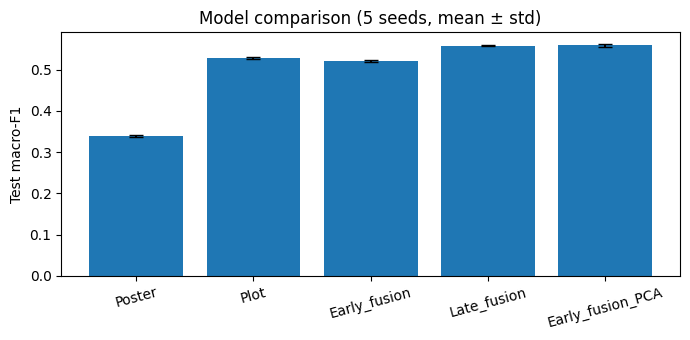

In [12]:
def run_quiet(X, seed):
    m, _ = train(X, seed=seed, lr=1e-4, wd=1e-3)
    return predict(m, X[dv]), predict(m, X[te])
def score(Pdv, Pte): return evaluate(Pte, Y[te], tune_thresholds(Pdv, Y[dv]))

rows = []
for s in range(5):
    P = {'Poster': run_quiet(Xi, s), 'Plot': run_quiet(Xt, s),
         'Early_fusion': run_quiet(Xe, s), 'Early_fusion_PCA': run_quiet(Xe2, s)}
    al = alphas[np.argmax([average_precision_score(Y[dv], a*P['Poster'][0] + (1-a)*P['Plot'][0], average='macro') for a in alphas])]
    P['Late_fusion'] = (al*P['Poster'][0] + (1-al)*P['Plot'][0], al*P['Poster'][1] + (1-al)*P['Plot'][1])
    for name, (pdv, pte) in P.items(): rows.append({'model': name, 'seed': s, **score(pdv, pte)})
    print('Seed', s, 'done')

df = pd.DataFrame(rows)
summary = df.groupby('model')[['micro_F1','macro_F1','samples_F1','mAP']].agg(['mean','std']).round(4)
print(summary); summary.to_csv('results_5seeds.csv')

order = ['Poster','Plot','Early_fusion','Late_fusion','Early_fusion_PCA']
mean = df.groupby('model')['macro_F1'].mean()[order]; std = df.groupby('model')['macro_F1'].std()[order]
plt.figure(figsize=(7,3.5)); plt.bar(order, mean, yerr=std, capsize=5)
plt.ylabel('Test macro-F1'); plt.title('Model comparison (5 seeds, mean ± std)'); plt.xticks(rotation=15)
plt.tight_layout(); plt.savefig('model_comparison.png', dpi=150); plt.show()

## 9. Per-genre analysis

             Poster   Plot  Late_fusion  Early_fusion_PCA  Fusion_gain
Drama         0.700  0.792        0.811             0.810        0.018
Comedy        0.652  0.686        0.749             0.748        0.063
Romance       0.391  0.513        0.540             0.530        0.016
Thriller      0.448  0.565        0.623             0.623        0.058
Crime         0.310  0.631        0.642             0.644        0.014
Action        0.392  0.582        0.632             0.636        0.053
Adventure     0.325  0.509        0.528             0.535        0.026
Horror        0.440  0.690        0.746             0.744        0.054
Documentary   0.223  0.800        0.775             0.804        0.004
Mystery       0.166  0.362        0.369             0.366        0.005
Sci-Fi        0.308  0.668        0.659             0.681        0.013
Fantasy       0.255  0.443        0.455             0.452        0.009
Family        0.490  0.561        0.654             0.658        0.097
Biogra

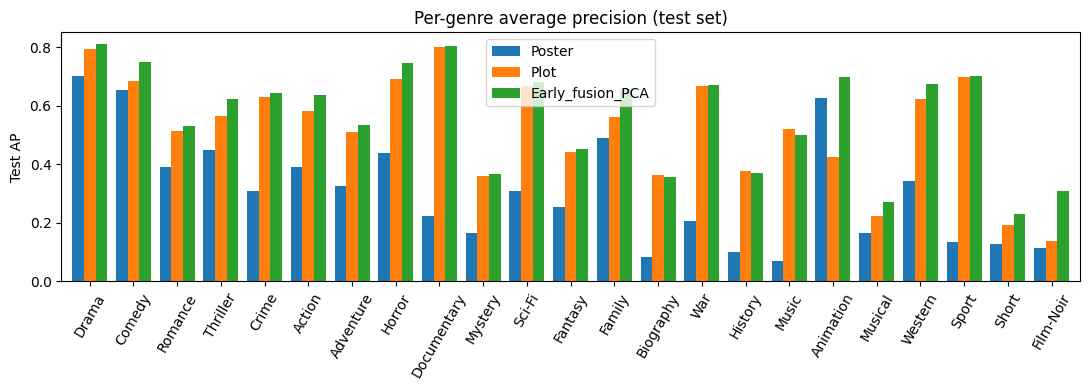

Correlation between fusion gain and genre frequency: -0.115


In [13]:
ap = lambda P: [average_precision_score(Y[te][:, j], P[:, j]) for j in range(23)]
pg = pd.DataFrame({'Poster': ap(Pte_img), 'Plot': ap(Pte_txt),
                   'Late_fusion': ap(Pte_late), 'Early_fusion_PCA': ap(Pte_early2)}, index=genres)
pg['Fusion_gain'] = pg['Early_fusion_PCA'] - pg['Plot']
print(pg.round(3)); pg.to_csv('per_genre_AP.csv')

ax = pg[['Poster', 'Plot', 'Early_fusion_PCA']].plot.bar(figsize=(11, 4), width=0.8)
ax.set_ylabel('Test AP'); ax.set_title('Per-genre average precision (test set)')
plt.xticks(rotation=60); plt.tight_layout(); plt.savefig('per_genre_AP.png', dpi=150); plt.show()

print('Correlation between fusion gain and genre frequency:',
      round(np.corrcoef(pg['Fusion_gain'], counts)[0, 1], 3))

## 10. Example predictions

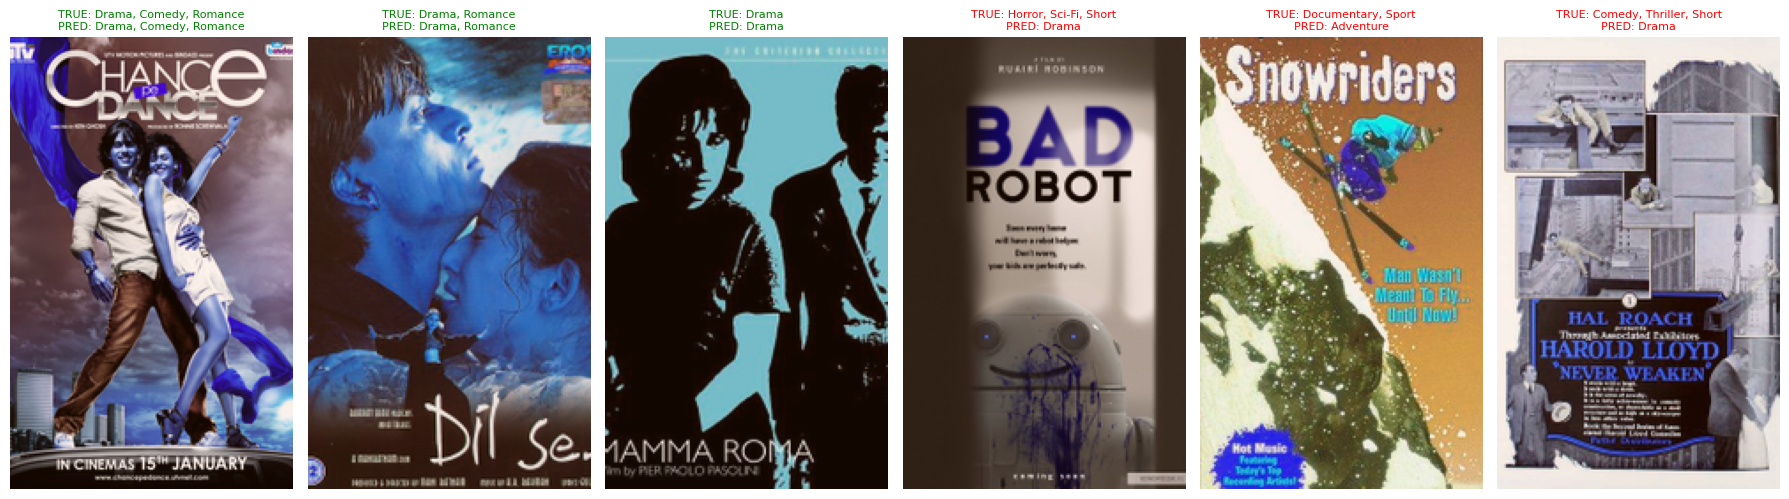

Share of test movies with NO correct genre: 0.053


In [14]:
th_e2 = tune_thresholds(Pdv_early2, Y[dv]); Yp = (Pte_early2 >= th_e2).astype(int); Yt = Y[te]
f1_each = np.array([f1_score(Yt[i], Yp[i], zero_division=0) for i in range(len(Yt))])
rng = np.random.default_rng(0)
pick = list(rng.choice(np.where(f1_each == 1)[0], 3, replace=False)) + \
       list(rng.choice(np.where(f1_each == 0)[0], 3, replace=False))
fig, axes = plt.subplots(1, 6, figsize=(18, 5))
for ax, i in zip(axes, pick):
    img = f['images'][18160 + i].transpose(1, 2, 0).astype('float32')
    img = (img - img.min()) / (img.max() - img.min())
    ax.imshow(img); ax.axis('off')
    true = ', '.join(g for g, y in zip(genres, Yt[i]) if y)
    pred = ', '.join(g for g, y in zip(genres, Yp[i]) if y)
    ax.set_title(f'TRUE: {true}\nPRED: {pred}', fontsize=8, color='green' if f1_each[i] == 1 else 'red')
plt.tight_layout(); plt.savefig('examples.png', dpi=150); plt.show()
print('Share of test movies with NO correct genre:', round((f1_each == 0).mean(), 3))

## 11. Efficiency and prediction bias

In [15]:
import time
eff = []
for name, X in [('Poster', Xi), ('Plot', Xt), ('Early_fusion', Xe), ('Early_fusion_PCA', Xe2)]:
    t0 = time.time(); m_, _ = train(X, lr=1e-4, wd=1e-3); t = time.time() - t0
    eff.append({'model': name, 'input_dim': X.shape[1],
                'params': sum(p.numel() for p in m_.parameters()), 'train_sec': round(t, 1)})
eff.append({'model': 'Late_fusion', 'input_dim': '4096 + 300', 'params': eff[0]['params'] + eff[1]['params'],
            'train_sec': round(eff[0]['train_sec'] + eff[1]['train_sec'], 1)})
eff = pd.DataFrame(eff); print(eff); eff.to_csv('efficiency.csv', index=False)

bias = pd.DataFrame({'true_rate': Yt.mean(0), 'pred_rate': Yp.mean(0)}, index=genres)
bias['pred/true'] = (bias['pred_rate'] / bias['true_rate']).round(2)
print(bias.round(3)); bias.to_csv('prediction_bias.csv')

              model   input_dim   params  train_sec
0            Poster        4096  2109463        5.8
1              Plot         300   165911        3.6
2      Early_fusion        4396  2263063        6.1
3  Early_fusion_PCA         600   319511        3.7
4       Late_fusion  4096 + 300  2275374        9.4
             true_rate  pred_rate  pred/true
Drama            0.531      0.694       1.31
Comedy           0.335      0.391       1.17
Romance          0.204      0.328       1.61
Thriller         0.201      0.281       1.40
Crime            0.149      0.194       1.30
Action           0.134      0.159       1.19
Adventure        0.105      0.173       1.64
Horror           0.106      0.118       1.12
Documentary      0.081      0.084       1.04
Mystery          0.079      0.095       1.20
Sci-Fi           0.075      0.077       1.03
Fantasy          0.075      0.077       1.03
Family           0.066      0.067       1.01
Biography        0.053      0.078       1.47
War          